## 1️⃣ Import Libraries

In [11]:
import json
import hashlib
from datetime import datetime, date
from getpass import getpass

import pandas as pd

print("Libraries imported successfully ✅")

Libraries imported successfully ✅



## 2️⃣ Custom Exceptions


In [12]:
class ATMError(Exception):
    """Base class for all ATM related errors."""
    pass

class InvalidPINError(ATMError):
    pass

class CardBlockedError(ATMError):
    pass

class InsufficientFundsError(ATMError):
    pass

class DailyLimitExceededError(ATMError):
    pass

class InvalidAmountError(ATMError):
    pass

class ATMOutOfCashError(ATMError):
    pass

class AccountNotFoundError(ATMError):
    pass

## 3️⃣ Transaction Class

In [14]:
class Transaction:
    _counter = 1000  # class variable for unique transaction IDs

    def __init__(self, txn_type, amount, balance_after, remarks=""):
        Transaction._counter += 1
        self.txn_id = f"TXN{Transaction._counter}"
        self.txn_type = txn_type
        self.amount = amount
        self.balance_after = balance_after
        self.remarks = remarks
        self.timestamp = datetime.now()

    def to_dict(self):
        return {
            "txn_id": self.txn_id,
            "type": self.txn_type,
            "amount": self.amount,
            "balance_after": self.balance_after,
            "remarks": self.remarks,
            "timestamp": self.timestamp.strftime("%Y-%m-%d %H:%M:%S"),
        }

    def __repr__(self):
        return (f"{self.timestamp:%d-%m-%Y %H:%M} | {self.txn_type:<12} | "
                f"₹{self.amount:>10,.2f} | Bal: ₹{self.balance_after:>10,.2f}")

## 4️⃣ Account Class

In [15]:

def hash_pin(pin: str) -> str:
    return hashlib.sha256(pin.encode()).hexdigest()


class Account:
    MIN_BALANCE = 500          # minimum balance to maintain
    DAILY_LIMIT = 25000        # max withdrawal per day
    MAX_PIN_ATTEMPTS = 3

    def __init__(self, card_number, holder_name, pin, balance=0.0):
        self.card_number = card_number
        self.holder_name = holder_name
        self._pin_hash = hash_pin(pin)
        self._balance = float(balance)
        self.transactions = []
        self.failed_attempts = 0
        self.is_blocked = False
        self._withdrawn_today = 0
        self._last_withdraw_date = date.today()

    # ---------- PIN handling ----------
    def verify_pin(self, pin):
        if self.is_blocked:
            raise CardBlockedError("Card is blocked. Please contact your bank.")
        if hash_pin(pin) == self._pin_hash:
            self.failed_attempts = 0
            return True
        self.failed_attempts += 1
        remaining = self.MAX_PIN_ATTEMPTS - self.failed_attempts
        if remaining <= 0:
            self.is_blocked = True
            raise CardBlockedError("Too many wrong attempts. Card has been BLOCKED.")
        raise InvalidPINError(f"Incorrect PIN. {remaining} attempt(s) left.")

    def change_pin(self, old_pin, new_pin):
        self.verify_pin(old_pin)
        if not (new_pin.isdigit() and len(new_pin) == 4):
            raise InvalidAmountError("New PIN must be exactly 4 digits.")
        if new_pin == old_pin:
            raise InvalidAmountError("New PIN cannot be the same as old PIN.")
        self._pin_hash = hash_pin(new_pin)
        self._record("PIN CHANGE", 0, "PIN updated")

    # ---------- Balance ----------
    @property
    def balance(self):
        return self._balance

    def _record(self, txn_type, amount, remarks=""):
        txn = Transaction(txn_type, amount, self._balance, remarks)
        self.transactions.append(txn)
        return txn

    def _reset_daily_limit_if_needed(self):
        if self._last_withdraw_date != date.today():
            self._withdrawn_today = 0
            self._last_withdraw_date = date.today()

    # ---------- Operations ----------
    def deposit(self, amount, remarks="Cash deposit"):
        if amount <= 0:
            raise InvalidAmountError("Deposit amount must be positive.")
        self._balance += amount
        return self._record("DEPOSIT", amount, remarks)

    def withdraw(self, amount, remarks="ATM withdrawal"):
        self._reset_daily_limit_if_needed()
        if amount <= 0:
            raise InvalidAmountError("Amount must be positive.")
        if self._balance - amount < self.MIN_BALANCE:
            raise InsufficientFundsError(
                f"Insufficient funds. Available to withdraw: "
                f"₹{max(0, self._balance - self.MIN_BALANCE):,.2f}")
        if self._withdrawn_today + amount > self.DAILY_LIMIT:
            raise DailyLimitExceededError(
                f"Daily limit exceeded. Remaining limit today: "
                f"₹{self.DAILY_LIMIT - self._withdrawn_today:,.2f}")
        self._balance -= amount
        self._withdrawn_today += amount
        return self._record("WITHDRAWAL", amount, remarks)

    def mini_statement(self, n=5):
        return self.transactions[-n:]

    def __repr__(self):
        masked = "XXXX-XXXX-" + self.card_number[-4:]
        return f"Account({self.holder_name}, {masked}, ₹{self._balance:,.2f})"

## 5️⃣ Bank Class

In [16]:
class Bank:
    def __init__(self, name):
        self.name = name
        self.accounts = {}

    def add_account(self, account):
        self.accounts[account.card_number] = account

    def get_account(self, card_number):
        if card_number not in self.accounts:
            raise AccountNotFoundError("Card not recognised.")
        return self.accounts[card_number]

    def transfer(self, from_acc, to_card, amount):
        to_acc = self.get_account(to_card)
        if to_acc is from_acc:
            raise InvalidAmountError("Cannot transfer to the same account.")
        if amount <= 0:
            raise InvalidAmountError("Amount must be positive.")
        if from_acc.balance - amount < Account.MIN_BALANCE:
            raise InsufficientFundsError("Insufficient funds for transfer.")
        # debit and credit (no daily-limit check for transfers)
        from_acc._balance -= amount
        from_acc._record("TRANSFER OUT", amount, f"To {to_acc.holder_name}")
        to_acc.deposit(amount, remarks=f"From {from_acc.holder_name}")
        to_acc.transactions[-1].txn_type = "TRANSFER IN"

## 6️⃣ Cash Dispenser Class

In [18]:
class CashDispenser:
    def __init__(self, notes=None):
        # denomination -> number of notes available
        self.notes = notes or {2000: 20, 500: 100, 200: 100, 100: 200}

    @property
    def total_cash(self):
        return sum(d * c for d, c in self.notes.items())

    def plan_dispense(self, amount):
        """Return a {denomination: count} plan without changing inventory."""
        if amount % 100 != 0:
            raise InvalidAmountError("Amount must be a multiple of ₹100.")
        if amount > self.total_cash:
            raise ATMOutOfCashError("ATM does not have enough cash.")
        remaining, plan = amount, {}
        for denom in sorted(self.notes, reverse=True):
            count = min(remaining // denom, self.notes[denom])
            if count:
                plan[denom] = count
                remaining -= denom * count
        if remaining != 0:
            raise ATMOutOfCashError("Cannot dispense this amount with available notes.")
        return plan

    def dispense(self, plan):
        for denom, count in plan.items():
            self.notes[denom] -= count

    def load(self, denom, count):
        self.notes[denom] = self.notes.get(denom, 0) + count


# Quick test
d = CashDispenser()
print("Total cash in ATM: ₹", f"{d.total_cash:,}")
print("Plan for ₹4,800:", d.plan_dispense(4800))

Total cash in ATM: ₹ 130,000
Plan for ₹4,800: {2000: 2, 500: 1, 200: 1, 100: 1}


## 7️⃣ ATM Class (Core Logic)

In [19]:
class ATM:
    def __init__(self, atm_id, bank, dispenser):
        self.atm_id = atm_id
        self.bank = bank
        self.dispenser = dispenser
        self.current_account = None

    # ---------- Session ----------
    def insert_card(self, card_number, pin):
        try:
            account = self.bank.get_account(card_number)
            account.verify_pin(pin)
            self.current_account = account
            print(f"✅ Welcome, {account.holder_name}!")
            return True
        except ATMError as e:
            print(f"❌ {e}")
            return False

    def eject_card(self):
        if self.current_account:
            print(f"👋 Thank you, {self.current_account.holder_name}. Please collect your card.")
        self.current_account = None

    def _require_session(self):
        if not self.current_account:
            raise ATMError("No card inserted.")

    # ---------- Operations ----------
    def check_balance(self):
        self._require_session()
        print(f"💰 Available balance: ₹{self.current_account.balance:,.2f}")
        return self.current_account.balance

    def withdraw(self, amount):
        try:
            self._require_session()
            plan = self.dispenser.plan_dispense(amount)   # 1. can ATM pay?
            self.current_account.withdraw(amount)          # 2. can account pay?
            self.dispenser.dispense(plan)                  # 3. give cash
            notes = ", ".join(f"₹{d} x {c}" for d, c in plan.items())
            print(f"💵 Please collect ₹{amount:,}  [{notes}]")
            print(f"   Remaining balance: ₹{self.current_account.balance:,.2f}")
            return True
        except ATMError as e:
            print(f"❌ {e}")
            return False

    def deposit(self, amount):
        try:
            self._require_session()
            if amount % 100 != 0:
                raise InvalidAmountError("Deposit must be a multiple of ₹100.")
            self.current_account.deposit(amount)
            print(f"✅ ₹{amount:,} deposited. New balance: ₹{self.current_account.balance:,.2f}")
            return True
        except ATMError as e:
            print(f"❌ {e}")
            return False

    def transfer(self, to_card, amount):
        try:
            self._require_session()
            self.bank.transfer(self.current_account, to_card, amount)
            print(f"✅ ₹{amount:,} transferred. New balance: ₹{self.current_account.balance:,.2f}")
            return True
        except ATMError as e:
            print(f"❌ {e}")
            return False

    def change_pin(self, old_pin, new_pin):
        try:
            self._require_session()
            self.current_account.change_pin(old_pin, new_pin)
            print("✅ PIN changed successfully.")
            return True
        except ATMError as e:
            print(f"❌ {e}")
            return False

    def mini_statement(self, n=5):
        self._require_session()
        acc = self.current_account
        print("=" * 72)
        print(f"MINI STATEMENT  |  {self.bank.name}  |  ATM: {self.atm_id}")
        print(f"Card: XXXX-XXXX-{acc.card_number[-4:]}   Name: {acc.holder_name}")
        print("-" * 72)
        txns = acc.mini_statement(n)
        if not txns:
            print("No transactions yet.")
        for t in txns:
            print(t)
        print("-" * 72)
        print(f"Available Balance: ₹{acc.balance:,.2f}")
        print("=" * 72)

## 8️⃣ Setting Up Sample Data

In [29]:
bank = Bank("Python National Bank")

bank.add_account(Account("4111222233334444", "Sai Deekshith",  "1234", 50000))
bank.add_account(Account("4555666677778888", "Keerthi priya", "4321", 12000))
bank.add_account(Account("4999000011112222", "Arjun Reddy",  "1111", 3000))

dispenser = CashDispenser()
atm = ATM("ATM-HYD-001", bank, dispenser)

for acc in bank.accounts.values():
    print(acc)
print(f"\nATM cash available: ₹{dispenser.total_cash:,}")

Account(Sai Deekshith, XXXX-XXXX-4444, ₹50,000.00)
Account(Keerthi priya, XXXX-XXXX-8888, ₹12,000.00)
Account(Arjun Reddy, XXXX-XXXX-2222, ₹3,000.00)

ATM cash available: ₹130,000


## 9️⃣ Automated Demo (Test Scenarios)


### Scenario 1: Successful login, balance, withdraw, deposit

In [30]:
atm.insert_card("4111222233334444", "1234")
atm.check_balance()
atm.withdraw(7800)
atm.deposit(2000)

✅ Welcome, Sai Deekshith!
💰 Available balance: ₹50,000.00
💵 Please collect ₹7,800  [₹2000 x 3, ₹500 x 3, ₹200 x 1, ₹100 x 1]
   Remaining balance: ₹42,200.00
✅ ₹2,000 deposited. New balance: ₹44,200.00


True

### Scenario 2: Invalid withdrawal amounts

In [31]:
atm.withdraw(550)      # not a multiple of 100
atm.withdraw(-100)     # negative
atm.withdraw(60000)    # more than balance

❌ Amount must be a multiple of ₹100.
❌ Amount must be positive.
❌ Insufficient funds. Available to withdraw: ₹43,700.00


False

### Scenario 3: Daily withdrawal limit (₹25,000)

In [32]:
atm.withdraw(15000)
atm.withdraw(5000)     # withdrawn today = 22,800; +5,000 would exceed ₹25,000

💵 Please collect ₹15,000  [₹2000 x 7, ₹500 x 2]
   Remaining balance: ₹29,200.00
❌ Daily limit exceeded. Remaining limit today: ₹2,200.00


False

### Scenario 4: Fund transfer & PIN change

In [33]:
atm.transfer("4555666677778888", 3000)
atm.transfer("0000000000000000", 100)   # unknown card
atm.change_pin("1234", "9876")

✅ ₹3,000 transferred. New balance: ₹26,200.00
❌ Card not recognised.
✅ PIN changed successfully.


True

### Scenario 5: Mini statement

In [34]:
atm.mini_statement()
atm.eject_card()

MINI STATEMENT  |  Python National Bank  |  ATM: ATM-HYD-001
Card: XXXX-XXXX-4444   Name: Sai Deekshith
------------------------------------------------------------------------
12-10-2026 19:45 | WITHDRAWAL   | ₹  7,800.00 | Bal: ₹ 42,200.00
12-10-2026 19:45 | DEPOSIT      | ₹  2,000.00 | Bal: ₹ 44,200.00
12-10-2026 19:46 | WITHDRAWAL   | ₹ 15,000.00 | Bal: ₹ 29,200.00
12-10-2026 19:46 | TRANSFER OUT | ₹  3,000.00 | Bal: ₹ 26,200.00
12-10-2026 19:46 | PIN CHANGE   | ₹      0.00 | Bal: ₹ 26,200.00
------------------------------------------------------------------------
Available Balance: ₹26,200.00
👋 Thank you, Sai Deekshith. Please collect your card.


### Scenario 6: Wrong PIN → card blocked after 3 attempts


In [35]:
for attempt_pin in ["0000", "1112", "2222", "1111"]:
    print(f"Trying PIN {attempt_pin}: ", end="")
    atm.insert_card("4999000011112222", attempt_pin)

Trying PIN 0000: ❌ Incorrect PIN. 2 attempt(s) left.
Trying PIN 1112: ❌ Incorrect PIN. 1 attempt(s) left.
Trying PIN 2222: ❌ Too many wrong attempts. Card has been BLOCKED.
Trying PIN 1111: ❌ Card is blocked. Please contact your bank.


### Scenario 7: Minimum balance rule & ATM cash inventory

In [36]:
atm.insert_card("4555666677778888", "4321")
atm.check_balance()
# Balance is ₹15,000 (₹12,000 + ₹3,000 transfer from Ravi)
atm.withdraw(14600)   # would leave ₹400 (< ₹500 minimum) -> rejected
atm.withdraw(14500)   # leaves exactly ₹500 -> allowed
atm.eject_card()

print("\nATM notes remaining:", dispenser.notes)
print(f"ATM cash remaining: ₹{dispenser.total_cash:,}")

✅ Welcome, Keerthi priya!
💰 Available balance: ₹15,000.00
❌ Insufficient funds. Available to withdraw: ₹14,500.00
💵 Please collect ₹14,500  [₹2000 x 7, ₹500 x 1]
   Remaining balance: ₹500.00
👋 Thank you, Keerthi priya. Please collect your card.

ATM notes remaining: {2000: 3, 500: 94, 200: 99, 100: 199}
ATM cash remaining: ₹92,700


## 🔟 Interactive ATM Menu

In [37]:
def read_amount(prompt):
    try:
        return int(input(prompt))
    except ValueError:
        print("❌ Please enter a valid number.")
        return None


def run_atm(atm, hide_pin=True):
    print("\n" + "=" * 40)
    print(f"   🏧  {atm.bank.name}")
    print("=" * 40)
    card = input("Insert card (enter card number): ").strip()
    pin = getpass("Enter PIN: ") if hide_pin else input("Enter PIN: ")
    if not atm.insert_card(card, pin):
        return

    menu = """
------------- MAIN MENU -------------
1. Balance Enquiry
2. Withdraw Cash
3. Deposit Cash
4. Fund Transfer
5. Change PIN
6. Mini Statement
7. Exit
-------------------------------------"""
    while True:
        print(menu)
        choice = input("Choose an option (1-7): ").strip()
        if choice == "1":
            atm.check_balance()
        elif choice == "2":
            print("Quick cash: a) ₹500  b) ₹1000  c) ₹2000  d) Other")
            q = input("Select: ").strip().lower()
            amount = {"a": 500, "b": 1000, "c": 2000}.get(q) or read_amount("Enter amount: ₹")
            if amount:
                atm.withdraw(amount)
        elif choice == "3":
            amount = read_amount("Enter deposit amount: ₹")
            if amount:
                atm.deposit(amount)
        elif choice == "4":
            to_card = input("Recipient card number: ").strip()
            amount = read_amount("Amount to transfer: ₹")
            if amount:
                atm.transfer(to_card, amount)
        elif choice == "5":
            old = getpass("Old PIN: ") if hide_pin else input("Old PIN: ")
            new = getpass("New 4-digit PIN: ") if hide_pin else input("New PIN: ")
            atm.change_pin(old, new)
        elif choice == "6":
            atm.mini_statement()
        elif choice == "7":
            atm.eject_card()
            break
        else:
            print("❌ Invalid option. Try again.")

print("Interactive ATM ready. Run:  run_atm(atm)")

Interactive ATM ready. Run:  run_atm(atm)


## 1️⃣1️⃣ Saving & Loading Data (JSON)

In [38]:
def save_bank(bank, filename="bank_data.json"):
    data = {}
    for card, acc in bank.accounts.items():
        data[card] = {
            "holder_name": acc.holder_name,
            "pin_hash": acc._pin_hash,
            "balance": acc.balance,
            "is_blocked": acc.is_blocked,
            "transactions": [t.to_dict() for t in acc.transactions],
        }
    with open(filename, "w") as f:
        json.dump({"bank": bank.name, "accounts": data}, f, indent=2)
    print(f"💾 Saved {len(data)} accounts to {filename}")


def load_bank(filename="bank_data.json"):
    with open(filename) as f:
        raw = json.load(f)
    new_bank = Bank(raw["bank"])
    for card, d in raw["accounts"].items():
        acc = Account(card, d["holder_name"], "0000", d["balance"])
        acc._pin_hash = d["pin_hash"]
        acc.is_blocked = d["is_blocked"]
        new_bank.add_account(acc)
    print(f"📂 Loaded {len(new_bank.accounts)} accounts from {filename}")
    return new_bank, raw


save_bank(bank)
loaded_bank, raw_data = load_bank()
for acc in loaded_bank.accounts.values():
    print(acc, "| blocked:", acc.is_blocked)

💾 Saved 3 accounts to bank_data.json
📂 Loaded 3 accounts from bank_data.json
Account(Sai Deekshith, XXXX-XXXX-4444, ₹26,200.00) | blocked: False
Account(Keerthi priya, XXXX-XXXX-8888, ₹500.00) | blocked: False
Account(Arjun Reddy, XXXX-XXXX-2222, ₹3,000.00) | blocked: True


## 1️⃣2️⃣ Transaction Analytics with pandas

In [39]:
rows = []
for card, d in raw_data["accounts"].items():
    for t in d["transactions"]:
        rows.append({**t, "holder": d["holder_name"]})

df = pd.DataFrame(rows)
df

,txn_id,type,amount,balance_after,remarks,timestamp,holder
0,TXN1008,WITHDRAWAL,7800,42200.0,ATM withdrawal,2026-10-12 19:45:59,Sai Deekshith
1,TXN1009,DEPOSIT,2000,44200.0,Cash deposit,2026-10-12 19:45:59,Sai Deekshith
2,TXN1010,WITHDRAWAL,15000,29200.0,ATM withdrawal,2026-10-12 19:46:04,Sai Deekshith
3,TXN1011,TRANSFER OUT,3000,26200.0,To Keerthi priya,2026-10-12 19:46:07,Sai Deekshith
4,TXN1013,PIN CHANGE,0,26200.0,PIN updated,2026-10-12 19:46:07,Sai Deekshith
5,TXN1012,TRANSFER IN,3000,15000.0,From Sai Deekshith,2026-10-12 19:46:07,Keerthi priya
6,TXN1014,WITHDRAWAL,14500,500.0,ATM withdrawal,2026-10-12 19:46:13,Keerthi priya


In [40]:
print("Transactions by type:")
print(df["type"].value_counts(), "\n")

summary = (df[df["type"] != "PIN CHANGE"]
           .pivot_table(index="holder", columns="type", values="amount",
                        aggfunc="sum", fill_value=0))
summary

Transactions by type:
type
WITHDRAWAL      3
DEPOSIT         1
TRANSFER OUT    1
PIN CHANGE      1
TRANSFER IN     1
Name: count, dtype: int64 



type,DEPOSIT,TRANSFER IN,TRANSFER OUT,WITHDRAWAL
holder,,,,
Keerthi priya,0,3000,0,14500
Sai Deekshith,2000,0,3000,22800


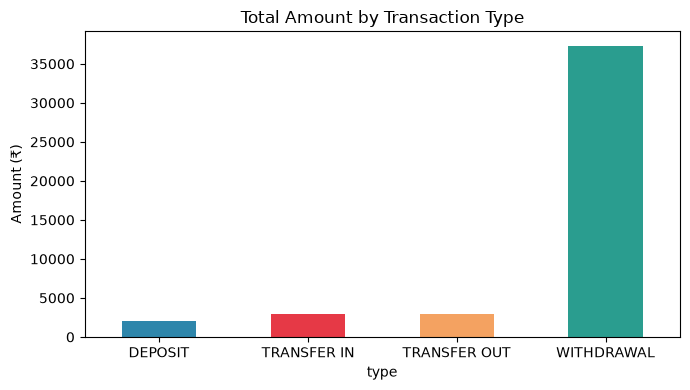

In [43]:
import matplotlib.pyplot as plt

amounts = df[df["type"] != "PIN CHANGE"].groupby("type")["amount"].sum()
amounts.plot(kind="bar", color=["#2E86AB", "#E63946", "#F4A261", "#2A9D8F"], figsize=(7, 4))
plt.title("Total Amount by Transaction Type")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()